=== 1. 변수 × 결함 유형 상관계수 ===
                       Pastry  Z_Scratch  K_Scatch  Stains  Dirtiness  Bumps  Other_Faults
X_Minimum               0.135     -0.229    -0.419   0.074      0.104  0.221         0.165
X_Maximum               0.120     -0.258    -0.336   0.061      0.097  0.202         0.146
Y_Minimum               0.036     -0.063    -0.000  -0.067      0.064  0.126        -0.084
Y_Maximum               0.036     -0.063    -0.000  -0.067      0.064  0.126        -0.084
Pixels_Areas           -0.077     -0.088     0.557  -0.071     -0.051 -0.164        -0.185
X_Perimeter            -0.075     -0.061     0.455  -0.068     -0.038 -0.140        -0.143
Y_Perimeter            -0.018     -0.026     0.203  -0.036     -0.010 -0.071        -0.067
Sum_of_Luminosity      -0.084     -0.100     0.617  -0.078     -0.055 -0.180        -0.206
Minimum_of_Luminosity  -0.075      0.050    -0.461   0.183      0.093  0.079         0.228
Maximum_of_Luminosity  -0.059     -0.189     0.186   0.090     

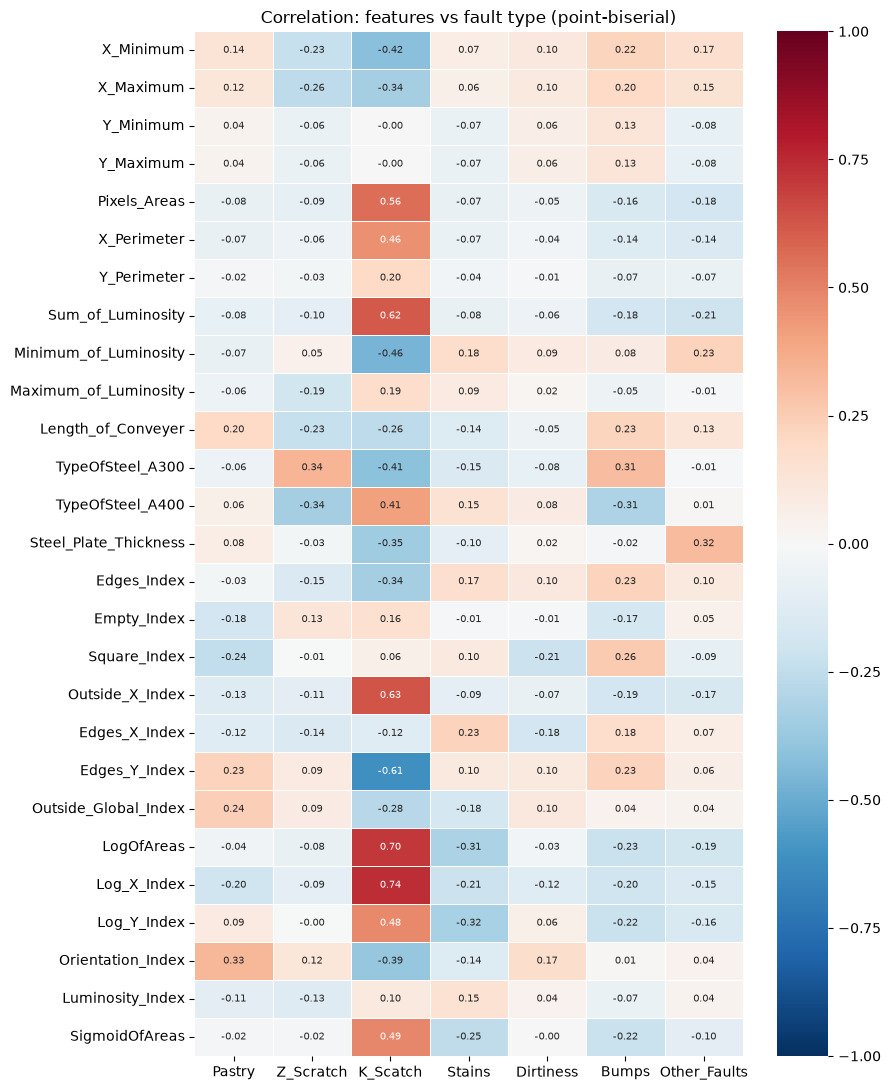


=== 2. 결함 유형별 표준화 평균 ===
fault_type             Pastry  Z_Scratch  K_Scatch  Stains  Dirtiness  Bumps  Other_Faults
X_Minimum                0.45      -0.69     -0.83    0.38       0.61   0.43          0.23
X_Maximum                0.40      -0.78     -0.67    0.31       0.57   0.39          0.20
Y_Minimum                0.12      -0.19     -0.00   -0.34       0.38   0.25         -0.12
Y_Maximum                0.12      -0.19     -0.00   -0.34       0.38   0.25         -0.12
Pixels_Areas            -0.26      -0.27      1.11   -0.36      -0.30  -0.32         -0.25
X_Perimeter             -0.25      -0.18      0.91   -0.34      -0.22  -0.27         -0.20
Y_Perimeter             -0.06      -0.08      0.40   -0.18      -0.06  -0.14         -0.09
Sum_of_Luminosity       -0.28      -0.30      1.23   -0.40      -0.32  -0.35         -0.28
Minimum_of_Luminosity   -0.25       0.15     -0.92    0.93       0.54   0.15          0.31
Maximum_of_Luminosity   -0.20      -0.57      0.37    0.46      

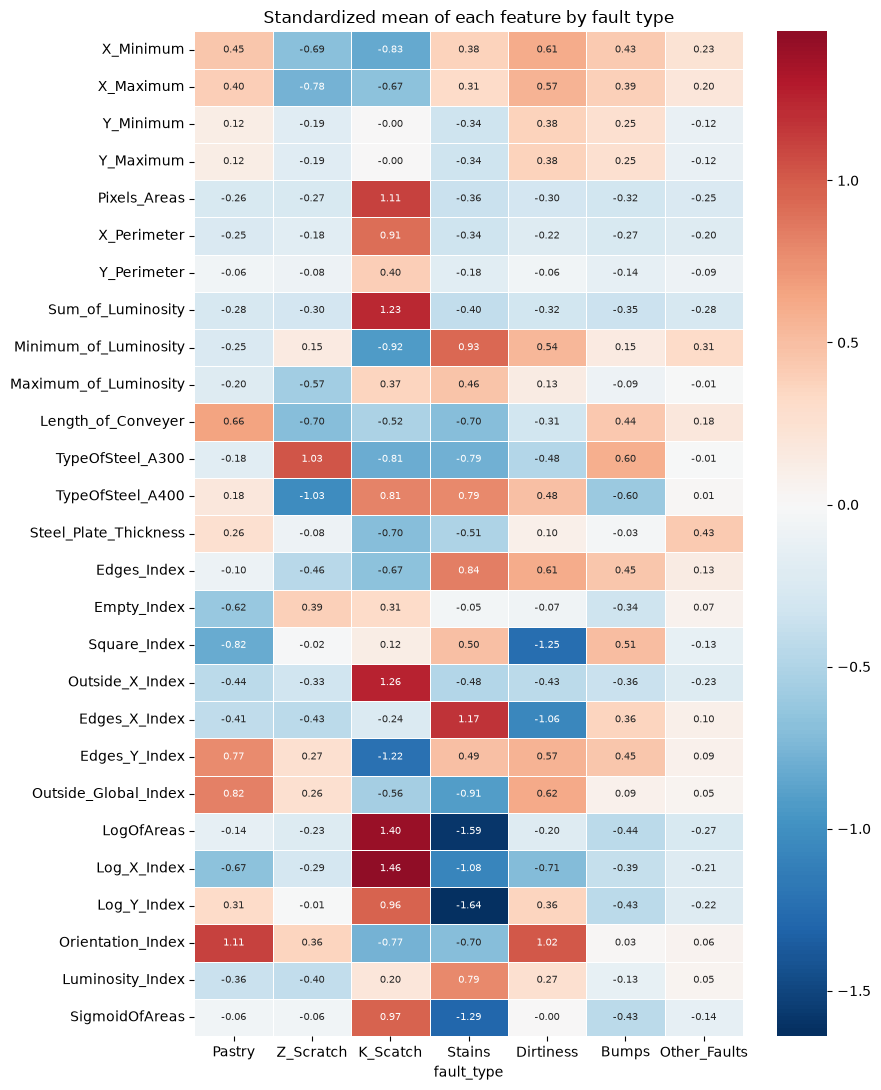


=== 3. 변수별 결함 유형 구분력 (Eta² 내림차순) ===
                   변수  Eta²  Kruskal H  p-value    MI
          Log_X_Index 0.580      809.5 1.4e-171 0.406
           LogOfAreas 0.564      786.3 1.4e-166 0.437
        Edges_Y_Index 0.419      715.3 3.1e-151 0.331
      Outside_X_Index 0.404      821.7 3.2e-174 0.534
    Sum_of_Luminosity 0.382      828.0 1.4e-175 0.448
          Log_Y_Index 0.352      667.8 5.5e-141 0.370
     TypeOfSteel_A300 0.344      666.7 9.7e-141 0.215
     TypeOfSteel_A400 0.344      666.7 9.7e-141 0.217
         Pixels_Areas 0.311      786.3 1.4e-166 0.432
       SigmoidOfAreas 0.298      705.2 4.6e-149 0.376
    Orientation_Index 0.279      563.7 1.6e-118 0.408
            X_Minimum 0.277      618.1 2.9e-130 0.502
Minimum_of_Luminosity 0.257      503.4 1.6e-105 0.394
            X_Maximum 0.222      426.0  7.3e-89 0.511
   Length_of_Conveyer 0.210      398.0  7.7e-83 0.573
          X_Perimeter 0.209      734.5 2.2e-155 0.409
          Edges_Index 0.199      404.7  2.7e

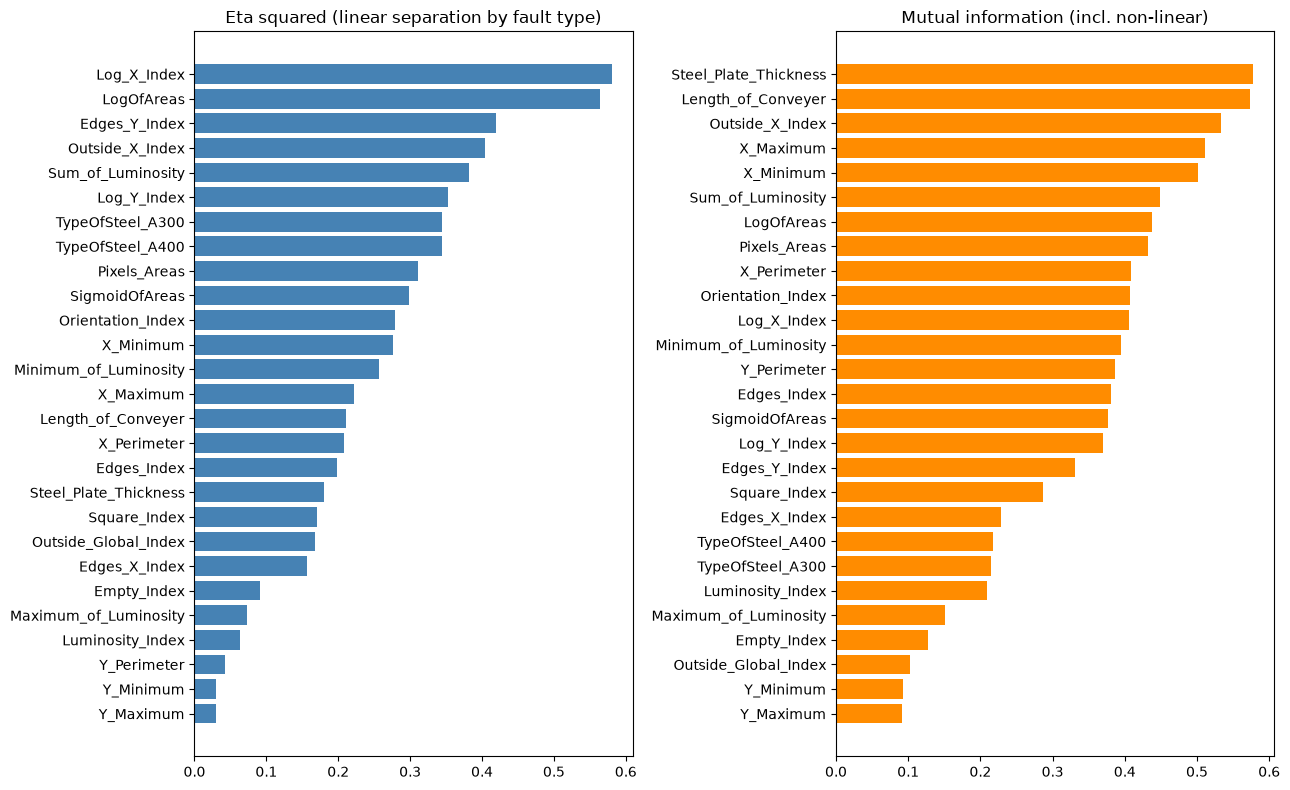


=== 4. 결함 유형별 상관이 가장 큰 변수 Top 3 (절대값 기준) ===
Pastry       : Orientation_Index(+0.33), Outside_Global_Index(+0.24), Square_Index(-0.24)
Z_Scratch    : TypeOfSteel_A300(+0.34), TypeOfSteel_A400(-0.34), X_Maximum(-0.26)
K_Scatch     : Log_X_Index(+0.74), LogOfAreas(+0.70), Outside_X_Index(+0.63)
Stains       : Log_Y_Index(-0.32), LogOfAreas(-0.31), SigmoidOfAreas(-0.25)
Dirtiness    : Square_Index(-0.21), Edges_X_Index(-0.18), Orientation_Index(+0.17)
Bumps        : TypeOfSteel_A300(+0.31), TypeOfSteel_A400(-0.31), Square_Index(+0.26)
Other_Faults : Steel_Plate_Thickness(+0.32), Minimum_of_Luminosity(+0.23), Sum_of_Luminosity(-0.21)


In [1]:
"""
강판 결함 데이터: 각 입력 변수와 결함 유형(7종)의 관계 분석
1) 변수 × 결함 유형 상관계수 히트맵 (점이연 상관 = 결함 여부 0/1과의 Pearson 상관)
2) 결함 유형별 표준화 평균 히트맵 (어느 유형에서 값이 높고 낮은지)
3) 변수별 결함 유형 구분력 순위 (Eta², Kruskal-Wallis 검정, 상호정보량)
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal
from sklearn.feature_selection import mutual_info_classif

# ---------------------------------------------------------------
# 0. 데이터 준비
# ---------------------------------------------------------------
df = pd.read_csv("steel_plates_faults.csv")

target_cols = ["Pastry", "Z_Scratch", "K_Scatch", "Stains",
               "Dirtiness", "Bumps", "Other_Faults"]
feature_cols = [c for c in df.columns if c not in target_cols]

df["fault_type"] = df[target_cols].idxmax(axis=1)
X = df[feature_cols]
y = df["fault_type"]

# ---------------------------------------------------------------
# 1. 변수 × 결함 유형 상관계수 (점이연 상관)
#    각 결함 유형 열(0/1)과 입력 변수의 Pearson 상관
#    +면 해당 유형에서 값이 큰 편, -면 작은 편
# ---------------------------------------------------------------
corr = pd.DataFrame(
    {t: X.corrwith(df[t]) for t in target_cols}
).round(3)

print("=== 1. 변수 × 결함 유형 상관계수 ===")
print(corr.to_string())

plt.figure(figsize=(9, 11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, annot_kws={"size": 7})
plt.title("Correlation: features vs fault type (point-biserial)")
plt.tight_layout()
plt.savefig("1_corr_feature_vs_fault.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# 2. 결함 유형별 표준화 평균 (Z-score 평균)
#    변수 단위가 제각각이므로 표준화 후 유형별 평균 비교
#    +1이면 전체 평균보다 1 표준편차 높음
# ---------------------------------------------------------------
X_std = (X - X.mean()) / X.std()
group_mean = X_std.groupby(y).mean().T[target_cols].round(2)

print("\n=== 2. 결함 유형별 표준화 평균 ===")
print(group_mean.to_string())

plt.figure(figsize=(9, 11))
sns.heatmap(group_mean, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            linewidths=0.5, annot_kws={"size": 7})
plt.title("Standardized mean of each feature by fault type")
plt.tight_layout()
plt.savefig("2_group_mean_by_fault.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# 3. 변수별 결함 유형 구분력
#    - Eta²: 변수 분산 중 결함 유형으로 설명되는 비율 (0~1, 클수록 구분력 높음)
#    - Kruskal-Wallis: 7개 유형의 분포가 같은지 비모수 검정 (이상치·비정규 분포에 강함)
#    - 상호정보량(MI): 비선형 관계까지 포함한 정보량
# ---------------------------------------------------------------
def eta_squared(x, groups):
    grand = x.mean()
    ss_between = sum(len(g) * (g.mean() - grand) ** 2 for _, g in x.groupby(groups))
    ss_total = ((x - grand) ** 2).sum()
    return ss_between / ss_total

rows = []
for col in feature_cols:
    groups = [X.loc[y == t, col] for t in target_cols]
    h, p = kruskal(*groups)
    rows.append({"변수": col,
                 "Eta²": eta_squared(X[col], y),
                 "Kruskal H": h,
                 "p-value": p})

summary = pd.DataFrame(rows)
summary["MI"] = mutual_info_classif(X, y, random_state=42)
summary = summary.sort_values("Eta²", ascending=False).reset_index(drop=True)

print("\n=== 3. 변수별 결함 유형 구분력 (Eta² 내림차순) ===")
print(summary.round({"Eta²": 3, "Kruskal H": 1, "MI": 3})
             .assign(**{"p-value": summary["p-value"].map("{:.1e}".format)})
             .to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 8))
s1 = summary.sort_values("Eta²")
axes[0].barh(s1["변수"], s1["Eta²"], color="steelblue")
axes[0].set_title("Eta squared (linear separation by fault type)")
s2 = summary.sort_values("MI")
axes[1].barh(s2["변수"], s2["MI"], color="darkorange")
axes[1].set_title("Mutual information (incl. non-linear)")
plt.tight_layout()
plt.savefig("3_feature_importance_by_fault.png", dpi=150)
plt.show()

# ---------------------------------------------------------------
# 4. 결함 유형별로 가장 관련이 큰 변수 Top 3
# ---------------------------------------------------------------
print("\n=== 4. 결함 유형별 상관이 가장 큰 변수 Top 3 (절대값 기준) ===")
for t in target_cols:
    top = corr[t].abs().sort_values(ascending=False).head(3).index
    items = ", ".join(f"{c}({corr.loc[c, t]:+.2f})" for c in top)
    print(f"{t:13s}: {items}")